# Data Understanding

## Import Libraries dan Raw Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

df = pd.read_csv("Automobile Sales data.csv")

df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,"2,871.00",24/02/2018,828,Shipped,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small
1,10121,34,81.35,5,"2,765.90",07/05/2018,757,Shipped,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small
2,10134,41,94.74,2,"3,884.34",01/07/2018,703,Shipped,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,"3,746.70",25/08/2018,649,Shipped,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium
4,10168,36,96.66,1,"3,479.76",28/10/2018,586,Shipped,Motorcycles,95,S10_1678,Technics Stores Inc.,6505556809,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium


## Dataset Structure

In [2]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (2747, 20)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2747 entries, 0 to 2746
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ORDERNUMBER           2747 non-null   int64  
 1   QUANTITYORDERED       2747 non-null   int64  
 2   PRICEEACH             2747 non-null   float64
 3   ORDERLINENUMBER       2747 non-null   int64  
 4   SALES                 2747 non-null   float64
 5   ORDERDATE             2747 non-null   str    
 6   DAYS_SINCE_LASTORDER  2747 non-null   int64  
 7   STATUS                2747 non-null   str    
 8   PRODUCTLINE           2747 non-null   str    
 9   MSRP                  2747 non-null   int64  
 10  PRODUCTCODE           2747 non-null   str    
 11  CUSTOMERNAME          2747 non-null   str    
 12  PHONE                 2747 non-null   str    
 13  ADDRESSLINE1          2747 non-null   str    
 14  CITY                  2747 non-null

## Descriptive Statistics — Numerical

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ORDERNUMBER,"2,747.00","10,259.76",91.88,"10,100.00","10,181.00","10,264.00","10,334.50","10,425.00"
QUANTITYORDERED,"2,747.00",35.10,9.76,6.00,27.00,35.00,43.00,97.00
PRICEEACH,"2,747.00",101.10,42.04,26.88,68.75,95.55,127.10,252.87
ORDERLINENUMBER,"2,747.00",6.49,4.23,1.00,3.00,6.00,9.00,18.00
SALES,"2,747.00","3,553.05","1,838.95",482.13,"2,204.35","3,184.80","4,503.09","14,082.80"
DAYS_SINCE_LASTORDER,"2,747.00","1,757.09",819.28,42.00,"1,077.00","1,761.00","2,436.50","3,562.00"
MSRP,"2,747.00",100.69,40.11,33.00,68.00,99.00,124.00,214.00


In [4]:

num_cols = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES",
    "MSRP"
]

stats = df[num_cols].agg([
    "mean", "median", "std",
    "min", "max", "skew"
]).T

display(stats)

,mean,median,std,min,max,skew
QUANTITYORDERED,35.10,35.00,9.76,6.00,97.00,0.37
PRICEEACH,101.10,95.55,42.04,26.88,252.87,0.70
SALES,"3,553.05","3,184.80","1,838.95",482.13,"14,082.80",1.16
MSRP,100.69,99.00,40.11,33.00,214.00,0.58


## Descriptive Statistics — Categorical

In [5]:
cat_cols = [
    "STATUS",
    "PRODUCTLINE",
    "COUNTRY",
    "DEALSIZE"
]

display(df[cat_cols].describe().T)

for col in cat_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts())

,count,unique,top,freq
STATUS,2747,6,Shipped,2541
PRODUCTLINE,2747,7,Classic Cars,949
COUNTRY,2747,19,USA,928
DEALSIZE,2747,3,Medium,1349



--- STATUS ---


STATUS
Shipped       2541
Cancelled       60
Resolved        47
On Hold         44
In Process      41
Disputed        14
Name: count, dtype: int64


--- PRODUCTLINE ---


PRODUCTLINE
Classic Cars        949
Vintage Cars        579
Motorcycles         313
Planes              304
Trucks and Buses    295
Ships               230
Trains               77
Name: count, dtype: int64


--- COUNTRY ---


COUNTRY
USA            928
Spain          342
France         314
Australia      185
UK             144
Italy          113
Finland         92
Norway          85
Singapore       79
Canada          70
Denmark         63
Germany         62
Sweden          57
Austria         55
Japan           52
Belgium         33
Switzerland     31
Philippines     26
Ireland         16
Name: count, dtype: int64


--- DEALSIZE ---


DEALSIZE
Medium    1349
Small     1246
Large      152
Name: count, dtype: int64

# Data Quality Assessment

## Missing Value Checking

In [6]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing)

,Missing Count,Missing Percentage
ORDERNUMBER,0,0.00
QUANTITYORDERED,0,0.00
PRICEEACH,0,0.00
ORDERLINENUMBER,0,0.00
SALES,0,0.00
ORDERDATE,0,0.00
DAYS_SINCE_LASTORDER,0,0.00
STATUS,0,0.00
PRODUCTLINE,0,0.00
MSRP,0,0.00


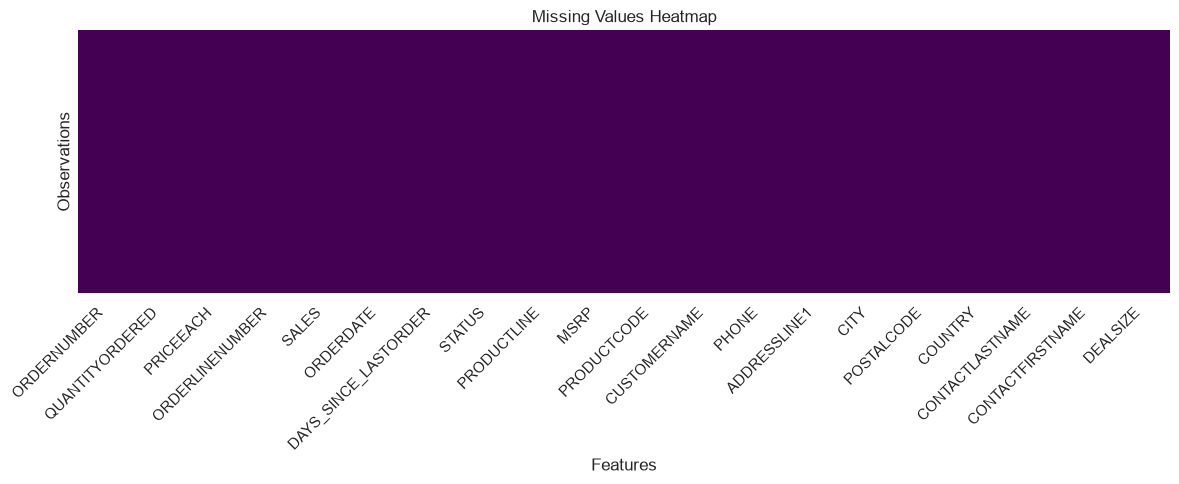

In [7]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis",
    yticklabels=False
)

plt.title("Missing Values Heatmap")
plt.xlabel("Features")
plt.ylabel("Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Duplicate Checking

In [8]:
print("Full Duplicate Rows:", df.duplicated().sum())

print(
    "Duplicate Order-Line:",
    df.duplicated(
        subset=["ORDERNUMBER", "ORDERLINENUMBER"]
    ).sum()
)

print(
    "Duplicate Order-Product:",
    df.duplicated(
        subset=["ORDERNUMBER", "PRODUCTCODE"]
    ).sum()
)

Full Duplicate Rows: 0
Duplicate Order-Line: 0
Duplicate Order-Product: 0


## Data Type Validation

In [9]:
df["ORDERDATE"] = pd.to_datetime(
    df["ORDERDATE"],
    format="%d/%m/%Y",
    errors="coerce"
)

print("Data Types:")
display(df.dtypes)

print("Invalid Dates:", df["ORDERDATE"].isna().sum())

print("Min Date:", df["ORDERDATE"].min())
print("Max Date:", df["ORDERDATE"].max())

Data Types:


ORDERNUMBER                      int64
QUANTITYORDERED                  int64
PRICEEACH                      float64
ORDERLINENUMBER                  int64
SALES                          float64
ORDERDATE               datetime64[us]
DAYS_SINCE_LASTORDER             int64
STATUS                             str
PRODUCTLINE                        str
MSRP                             int64
PRODUCTCODE                        str
CUSTOMERNAME                       str
PHONE                              str
ADDRESSLINE1                       str
CITY                               str
POSTALCODE                         str
COUNTRY                            str
CONTACTLASTNAME                    str
CONTACTFIRSTNAME                   str
DEALSIZE                           str
dtype: object

Invalid Dates: 0
Min Date: 2018-01-06 00:00:00
Max Date: 2020-05-31 00:00:00


## Data Consistency Checking

In [10]:
numeric_check = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES",
    "MSRP"
]

for col in numeric_check:
    print(
        col,
        "| Zero:", (df[col] == 0).sum(),
        "| Negative:", (df[col] < 0).sum()
    )

QUANTITYORDERED | Zero: 0 | Negative: 0
PRICEEACH | Zero: 0 | Negative: 0
SALES | Zero: 0 | Negative: 0
MSRP | Zero: 0 | Negative: 0


In [11]:

df["Calculated_Sales"] = (
    df["QUANTITYORDERED"] * df["PRICEEACH"]
)

df["Sales_Difference"] = (
    df["SALES"] - df["Calculated_Sales"]
).abs()

display(
    df[df["Sales_Difference"] > 0.01][
        ["ORDERNUMBER", "SALES",
         "Calculated_Sales", "Sales_Difference"]
    ]
)

,ORDERNUMBER,SALES,Calculated_Sales,Sales_Difference
41,10304,"10,172.70","10,172.68",0.02
42,10312,"11,623.70","11,623.68",0.02
1930,10405,"11,739.70","11,739.72",0.02
2049,10375,"10,039.60","10,039.64",0.04
2432,10388,"10,066.60","10,066.64",0.04


# Outlier Detection: Histogram, Boxplot & IQR

## Histogram — Numerical Distribution

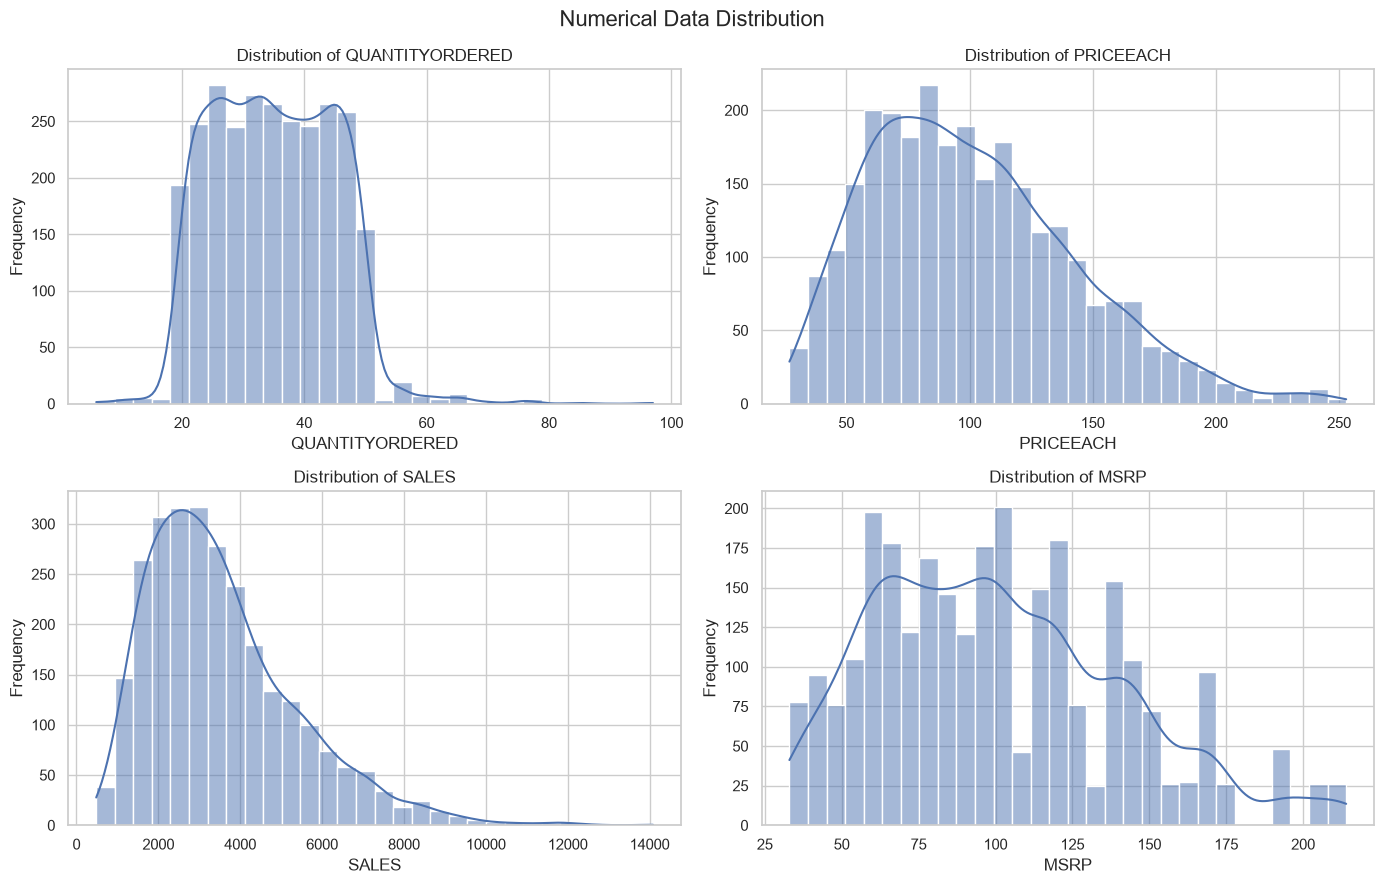

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(
        df[col],
        kde=True,
        bins=30,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.suptitle("Numerical Data Distribution", fontsize=16)
plt.tight_layout()
plt.show()

## Boxplot — Outlier Visualization

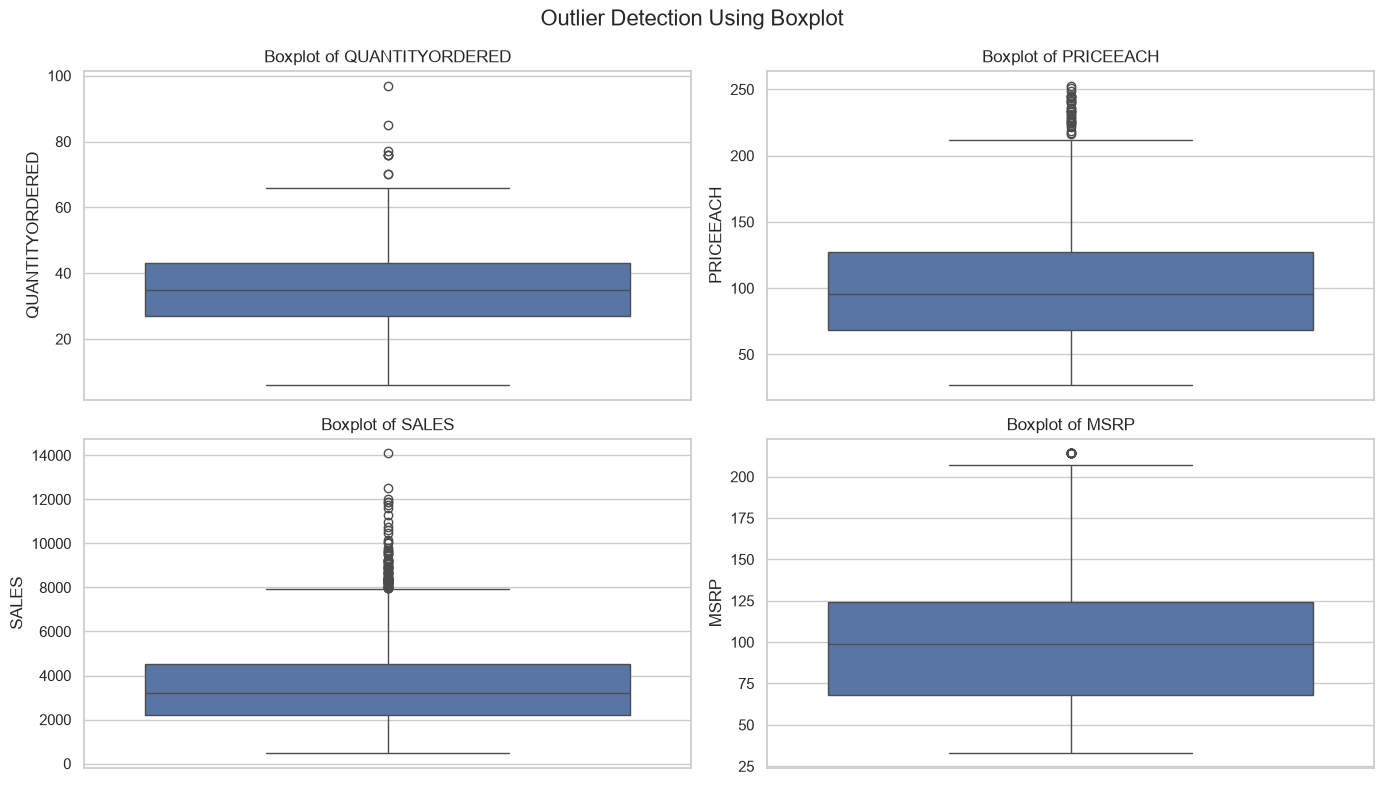

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(
        y=df[col],
        ax=ax
    )

    ax.set_title(f"Boxplot of {col}")
    ax.set_ylabel(col)

plt.suptitle("Outlier Detection Using Boxplot", fontsize=16)
plt.tight_layout()
plt.show()

## Calculate IQR

In [14]:
outlier_results = []

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Variable": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": (
            len(outliers) / len(df) * 100
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Variable,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,QUANTITYORDERED,27.00,43.00,16.00,3.00,67.00,8,0.29
1,PRICEEACH,68.74,127.10,58.35,-18.79,214.63,33,1.20
2,SALES,"2,204.35","4,503.09","2,298.74","-1,243.77","7,951.21",79,2.88
3,MSRP,68.00,124.00,56.00,-16.00,208.00,26,0.95


## Investigasi Outlier pada SALES

In [15]:
Q1 = df["SALES"].quantile(0.25)
Q3 = df["SALES"].quantile(0.75)

IQR = Q3 - Q1

upper_sales = Q3 + 1.5 * IQR

sales_outliers = df[
    df["SALES"] > upper_sales
].copy()

display(
    sales_outliers[
        [
            "ORDERNUMBER",
            "CUSTOMERNAME",
            "PRODUCTLINE",
            "QUANTITYORDERED",
            "PRICEEACH",
            "SALES",
            "STATUS"
        ]
    ].sort_values("SALES", ascending=False).head(15)
)

,ORDERNUMBER,CUSTOMERNAME,PRODUCTLINE,QUANTITYORDERED,PRICEEACH,SALES,STATUS
571,10407,The Sharp Gifts Warehouse,Vintage Cars,76,185.30,"14,082.80",On Hold
714,10322,Online Diecast Creations Co.,Vintage Cars,50,250.73,"12,536.50",Shipped
49,10424,Euro Shopping Channel,Classic Cars,50,240.02,"12,001.00",In Process
1020,10412,Euro Shopping Channel,Classic Cars,60,198.13,"11,887.80",Shipped
96,10403,"UK Collectables, Ltd.",Motorcycles,66,180.10,"11,886.60",Shipped
1930,10405,Mini Caravy,Classic Cars,76,154.47,"11,739.70",Shipped
42,10312,Mini Gifts Distributors Ltd.,Classic Cars,48,242.16,"11,623.70",Shipped
176,10127,Muscle Machine Inc,Classic Cars,46,245.20,"11,279.20",Shipped
28,10150,"Dragon Souveniers, Ltd.",Classic Cars,45,244.30,"10,993.50",Shipped
1779,10339,"Tokyo Collectables, Ltd",Vintage Cars,55,195.60,"10,758.00",Shipped


## Quantify the Impact of Outliers

In [16]:
outlier_revenue = sales_outliers["SALES"].sum()
total_revenue = df["SALES"].sum()

print("Outlier Rows:", len(sales_outliers))

print(
    "Outlier Revenue Contribution:",
    round(outlier_revenue / total_revenue * 100, 2),
    "%"
)

Outlier Rows: 79
Outlier Revenue Contribution: 7.41 %


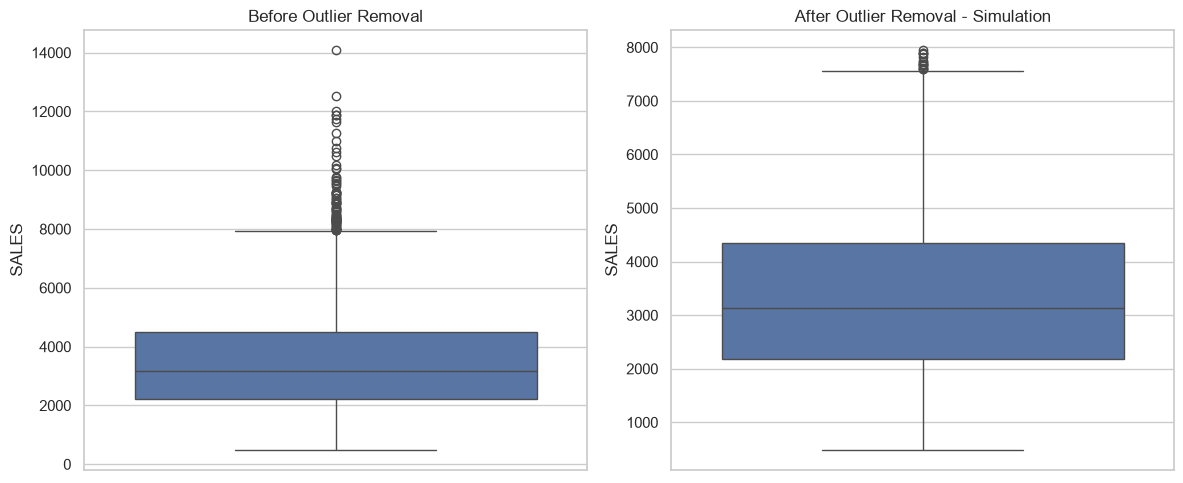

In [17]:
df_without_outliers = df[
    df["SALES"] <= upper_sales
].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["SALES"], ax=axes[0])
axes[0].set_title("Before Outlier Removal")

sns.boxplot(
    y=df_without_outliers["SALES"],
    ax=axes[1]
)
axes[1].set_title("After Outlier Removal - Simulation")

plt.tight_layout()
plt.show()

Keputusan cleaning: Untuk saat ini, kita pertahankan outlier yang tidak terbukti salah. Alasannya adalah data sales, quantity, dan harga memiliki variasi yang wajar untuk bisnis wholesale otomotif.

## Final Data Cleaning & Validation

## Standardize & Remove Invalid Records

In [18]:
df_clean = df.copy()

# Remove exact duplicates
df_clean = df_clean.drop_duplicates()

# Standardize text fields
text_cols = [
    "CUSTOMERNAME",
    "STATUS",
    "PRODUCTLINE",
    "COUNTRY",
    "CITY"
]

for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()

# Ensure positive transaction values
df_clean = df_clean[
    (df_clean["SALES"] > 0) &
    (df_clean["QUANTITYORDERED"] > 0) &
    (df_clean["PRICEEACH"] > 0)
].copy()

# Remove invalid essential fields
df_clean = df_clean.dropna(
    subset=[
        "ORDERDATE",
        "CUSTOMERNAME",
        "ORDERNUMBER",
        "SALES"
    ]
)

print("Cleaned Data Shape:", df_clean.shape)

Cleaned Data Shape: (2747, 22)


## Status Validation

In [19]:
# Status Validation

status_summary = df_clean.groupby("STATUS").agg(
    Total_Rows=("ORDERNUMBER", "size"),
    Total_Orders=("ORDERNUMBER", "nunique"),
    Revenue=("SALES", "sum")
).reset_index()

display(status_summary)

,STATUS,Total_Rows,Total_Orders,Revenue
0,Cancelled,60,4,"194,487.48"
1,Disputed,14,3,"72,212.86"
2,In Process,41,6,"144,729.96"
3,On Hold,44,4,"178,979.19"
4,Resolved,47,4,"150,718.28"
5,Shipped,2541,277,"9,019,093.94"


Karena analisa kedepan berfokus pada RFM, kita menggunakan hanya order berstatus Shipped. Ini merupakan asumsi operasional bahwa pengiriman telah selesai diproses.

In [20]:
df_rfm = df_clean[
    df_clean["STATUS"] == "Shipped"
].copy()

print("RFM Dataset Rows:", len(df_rfm))
print("Unique Orders:", df_rfm["ORDERNUMBER"].nunique())
print("Unique Customers:", df_rfm["CUSTOMERNAME"].nunique())
print("Total Revenue:", df_rfm["SALES"].sum())

RFM Dataset Rows: 2541
Unique Orders: 277
Unique Customers: 89
Total Revenue: 9019093.94


## Check Order-Level Consistency

In [21]:
order_validation = df_rfm.groupby("ORDERNUMBER").agg(
    Customer_Count=("CUSTOMERNAME", "nunique"),
    Date_Count=("ORDERDATE", "nunique")
)

print(
    "Orders with Multiple Customers:",
    (order_validation["Customer_Count"] > 1).sum()
)

print(
    "Orders with Multiple Dates:",
    (order_validation["Date_Count"] > 1).sum()
)

Orders with Multiple Customers: 0
Orders with Multiple Dates: 0


## Recheck Outliers After Filtering

In [22]:
for col in num_cols:
    Q1 = df_rfm[col].quantile(0.25)
    Q3 = df_rfm[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df_rfm[col] < lower) |
        (df_rfm[col] > upper)
    ).sum()

    print(f"{col}: {count} outliers")

QUANTITYORDERED: 4 outliers
PRICEEACH: 30 outliers
SALES: 73 outliers
MSRP: 0 outliers


In [23]:
df_rfm = df_rfm.drop(
    columns=["Calculated_Sales", "Sales_Difference"],
    errors="ignore"
)

df_rfm.to_csv(
    "automobile_sales_cleaned.csv",
    index=False
)

print("Data cleaning completed!")

Data cleaning completed!


Data Cleaning & Preparation

Dataset awal terdiri dari 2.747 baris dan 20 kolom, mencakup 298 transaksi dan 89 pelanggan unik.

Tidak ditemukan missing values, data duplikat, maupun duplikasi pada kombinasi nomor transaksi dan baris pesanan.

Kolom ORDERDATE telah diubah menjadi tipe data datetime, dengan periode transaksi Januari 2018 hingga Mei 2020.

Deteksi outlier dilakukan menggunakan Boxplot dan metode Interquartile Range (IQR). Ditemukan 79 outlier pada SALES, 33 pada PRICEEACH, 8 pada QUANTITYORDERED, dan 26 pada MSRP.

Outlier tetap dipertahankan karena nilai transaksi yang ekstrem berpotensi mencerminkan pembelian bernilai tinggi yang relevan untuk analisis segmentasi pelanggan.

Hanya transaksi berstatus Shipped yang digunakan dalam analisis RFM, sehingga dataset akhir terdiri dari 2.541 baris, 277 transaksi unik, dan 89 pelanggan.

Nilai Recency akan dihitung ulang berdasarkan tanggal transaksi terakhir setiap pelanggan, tanpa menggunakan kolom DAYS_SINCE_LASTORDER yang tersedia dalam dataset.

# EDA Univariate Analysis

## Distribution of Order Value

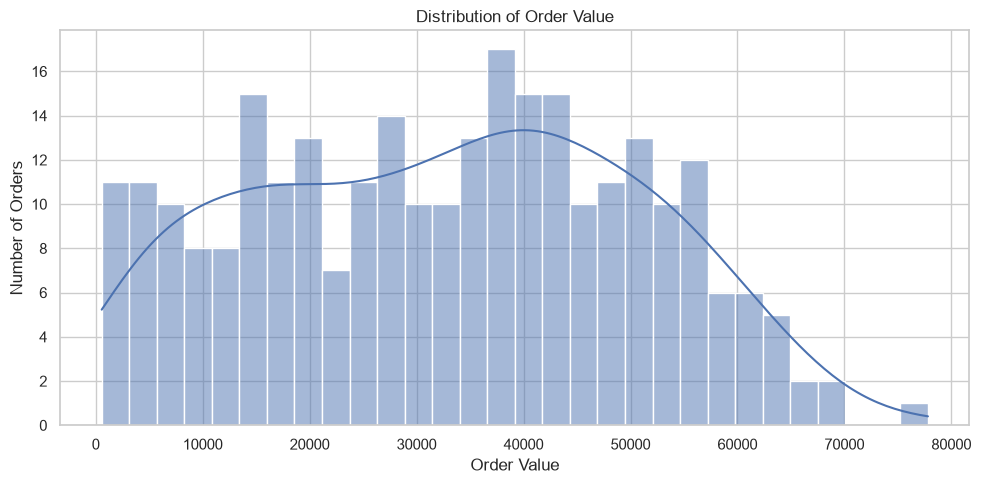

Descriptive Statistics:


count      277.00
mean    32,559.91
std     17,881.56
min        553.95
25%     17,114.43
50%     33,847.62
75%     46,802.27
max     77,809.37
Name: Order_Value, dtype: float64

Skewness: 0.01


In [24]:
# Univariate Analysis - Order Value Distribution

order_value = (
    df_rfm.groupby("ORDERNUMBER")["SALES"]
    .sum()
    .reset_index(name="Order_Value")
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=order_value,
    x="Order_Value",
    bins=30,
    kde=True
)

plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

print("Descriptive Statistics:")
display(order_value["Order_Value"].describe())

print(
    "Skewness:",
    round(order_value["Order_Value"].skew(), 3)
)

In [25]:
print("Order Value Skewness:",
      round(order_value["Order_Value"].skew(), 3))

print("Mean:",
      round(order_value["Order_Value"].mean(), 2))

print("Median:",
      round(order_value["Order_Value"].median(), 2))

Order Value Skewness: 0.01
Mean: 32559.91
Median: 33847.62


Order Value Distribution — Key Findings

Distribusi nilai transaksi relatif simetris (skewness = 0,01), dengan mean sebesar 32.559,91 dan median 33.847,62.

Standard deviation sebesar 17.881,56 menunjukkan variasi nilai transaksi yang cukup besar.

Sebanyak 50% transaksi memiliki nilai antara 17.114,43 hingga 46.802,27.

Conclusion: Meskipun distribusi nilai transaksi relatif simetris, variasi besaran pembelian menunjukkan pentingnya menganalisis akumulasi nilai transaksi setiap pelanggan untuk mengidentifikasi perbedaan customer value.

## Customer Revenue Distribution

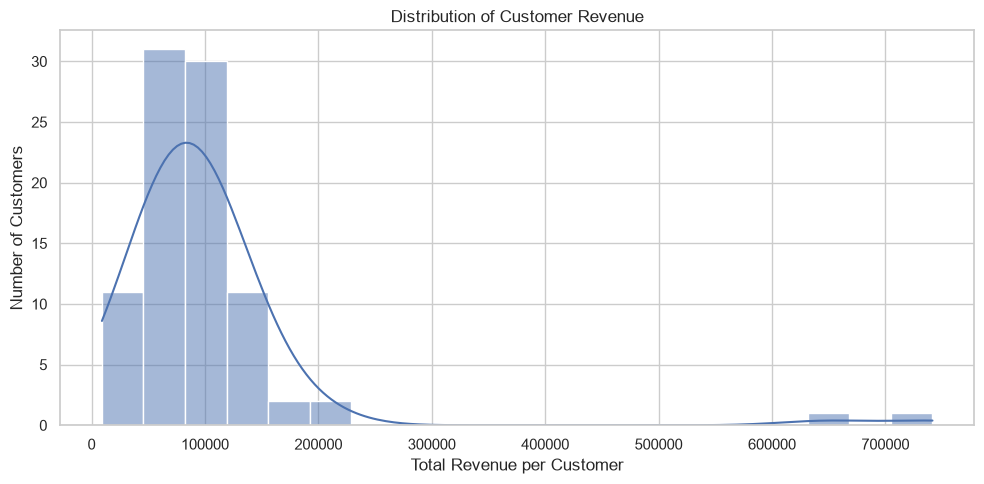

Descriptive Statistics:


count        89.00
mean    101,338.13
std      98,365.24
min       9,129.35
25%      64,834.32
50%      85,171.59
75%     113,961.15
max     741,512.50
Name: Total_Revenue, dtype: float64

Skewness: 5.161


In [26]:
# Univariate Analysis - Customer Revenue Distribution

customer_revenue = (
    df_rfm.groupby("CUSTOMERNAME")["SALES"]
    .sum()
    .reset_index(name="Total_Revenue")
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=customer_revenue,
    x="Total_Revenue",
    bins=20,
    kde=True
)

plt.title("Distribution of Customer Revenue")
plt.xlabel("Total Revenue per Customer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("Descriptive Statistics:")
display(customer_revenue["Total_Revenue"].describe())

print(
    "Skewness:",
    round(customer_revenue["Total_Revenue"].skew(), 3)
)

Customer Revenue Distribution — Key Findings

Distribusi Customer Revenue sangat right-skewed (skewness = 5,161), berbeda dengan distribusi Order Value yang relatif simetris (skewness = 0,010).

Rata-rata revenue per customer sebesar 101.338,13, lebih tinggi dibandingkan median sebesar 85.171,59.

Terdapat pelanggan dengan total revenue mencapai 741.512,50, menunjukkan ketimpangan nilai pembelian antarpelanggan.

Temuan ini mengindikasikan potensi revenue concentration dan menjadi dasar untuk mengidentifikasi high-value customers melalui RFM Analysis.

Conclusion: Perbedaan nilai pelanggan menunjukkan pentingnya segmentasi berdasarkan perilaku transaksi untuk memahami kontribusi masing-masing kelompok terhadap total revenue.

## Revenue Concentration Analysis

In [27]:
# Revenue Concentration Analysis

customer_sorted = customer_revenue.sort_values(
    "Total_Revenue", ascending=False
)

total_revenue = customer_sorted["Total_Revenue"].sum()

top_1 = customer_sorted.head(1)["Total_Revenue"].sum()
top_5 = customer_sorted.head(5)["Total_Revenue"].sum()
top_10 = customer_sorted.head(10)["Total_Revenue"].sum()

print("Top 1 Customer Contribution:",
      round(top_1 / total_revenue * 100, 2), "%")

print("Top 5 Customers Contribution:",
      round(top_5 / total_revenue * 100, 2), "%")

print("Top 10 Customers Contribution:",
      round(top_10 / total_revenue * 100, 2), "%")

display(customer_sorted.head(10))

Top 1 Customer Contribution: 8.22 %
Top 5 Customers Contribution: 21.74 %
Top 10 Customers Contribution: 30.02 %


,CUSTOMERNAME,Total_Revenue
32,Euro Shopping Channel,"741,512.50"
53,Mini Gifts Distributors Ltd.,"647,596.31"
6,"Australian Collectors, Co.","200,995.41"
55,Muscle Machine Inc,"197,736.94"
30,"Dragon Souveniers, Ltd.","172,989.68"
0,"AV Stores, Co.","157,807.81"
3,"Anna's Decorations, Ltd","153,996.13"
67,Salzburg Collectables,"149,798.63"
68,"Saveley & Henriot, Co.","142,874.25"
41,L'ordine Souveniers,"142,601.33"


Revenue Concentration — Key Findings

Top 10 pelanggan berkontribusi sebesar 30,02% terhadap total revenue, meskipun hanya mewakili 11,2% dari seluruh pelanggan.

Dua pelanggan terbesar, Euro Shopping Channel dan Mini Gifts Distributors Ltd., menyumbang sekitar 15,4% total revenue.

Distribusi revenue menunjukkan adanya perbedaan customer value, tetapi mayoritas revenue (69,98%) masih berasal dari pelanggan di luar Top 10.

Conclusion: Perbedaan kontribusi revenue antarpelanggan menunjukkan perlunya analisis lebih lanjut terhadap frekuensi dan aktivitas pembelian untuk mengidentifikasi segmen pelanggan bernilai tinggi.

## Customer Purchase Frequency Distribution

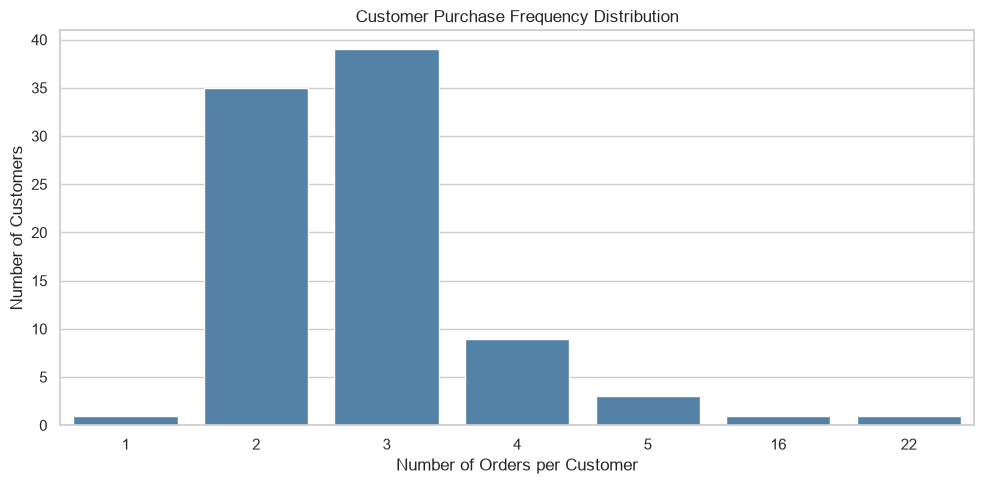

Descriptive Statistics:


count   89.00
mean     3.11
std      2.59
min      1.00
25%      2.00
50%      3.00
75%      3.00
max     22.00
Name: Frequency, dtype: float64

Skewness: 5.941


In [28]:
# Univariate Analysis - Customer Purchase Frequency

customer_frequency = (
    df_rfm.groupby("CUSTOMERNAME")["ORDERNUMBER"]
    .nunique()
    .reset_index(name="Frequency")
)

plt.figure(figsize=(10, 5))

sns.countplot(
    data=customer_frequency,
    x="Frequency",
    color="steelblue"
)

plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Orders per Customer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("Descriptive Statistics:")
display(customer_frequency["Frequency"].describe())

print(
    "Skewness:",
    round(customer_frequency["Frequency"].skew(), 3)
)

Customer Purchase Frequency — Key Findings

Distribusi Purchase Frequency sangat right-skewed (skewness = 5,941), dengan rata-rata 3,11 transaksi per pelanggan.

Sebanyak 83,1% pelanggan melakukan 2–3 transaksi selama periode pengamatan.

Terdapat dua pelanggan dengan frekuensi pembelian mencapai 16 dan 22 transaksi, jauh di atas median sebesar 3 transaksi.

Kesamaan pola distribusi Frequency dan Customer Revenue mengindikasikan potensi hubungan antara intensitas pembelian dan nilai pelanggan.

Conclusion: Perbedaan frekuensi transaksi menjadi dasar untuk menganalisis hubungan antara Frequency dan Monetary dalam RFM Analysis.

## Customer Recency Distribution

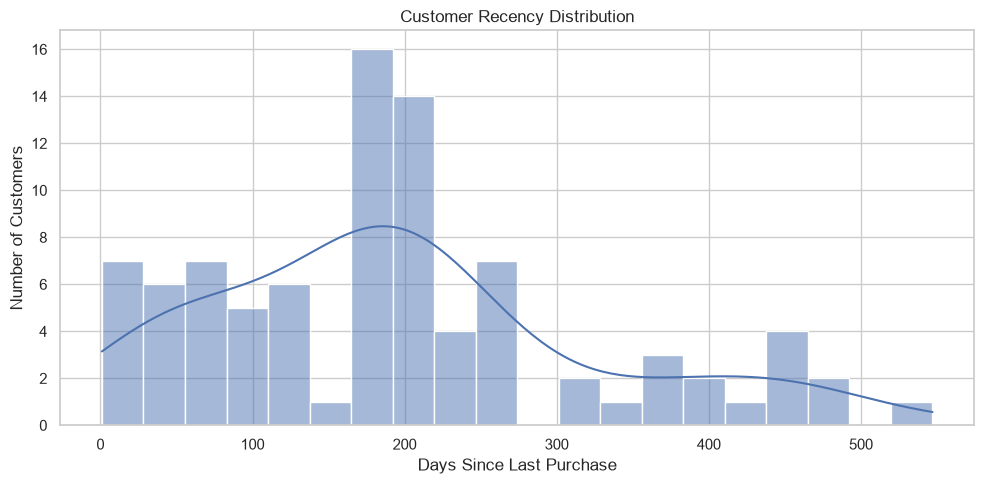

Descriptive Statistics:


count    89.00
mean    195.10
std     126.85
min       1.00
25%     105.00
50%     184.00
75%     251.00
max     547.00
Name: Recency, dtype: float64

Skewness: 0.735


In [29]:
# Univariate Analysis - Customer Recency

snapshot_date = (
    df_rfm["ORDERDATE"].max()
    + pd.Timedelta(days=1)
)

customer_recency = (
    df_rfm.groupby("CUSTOMERNAME")["ORDERDATE"]
    .max()
    .reset_index(name="Last_Purchase")
)

customer_recency["Recency"] = (
    snapshot_date - customer_recency["Last_Purchase"]
).dt.days

plt.figure(figsize=(10, 5))

sns.histplot(
    data=customer_recency,
    x="Recency",
    bins=20,
    kde=True
)

plt.title("Customer Recency Distribution")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("Descriptive Statistics:")
display(customer_recency["Recency"].describe())

print(
    "Skewness:",
    round(customer_recency["Recency"].skew(), 3)
)

Distribusi Recency bersifat moderately right-skewed. Terdapat kelompok pelanggan yang sudah relatif lama tidak bertransaksi dan berpotensi menjadi target strategi reaktivasi.

## Purchase Frequency vs Customer Revenue

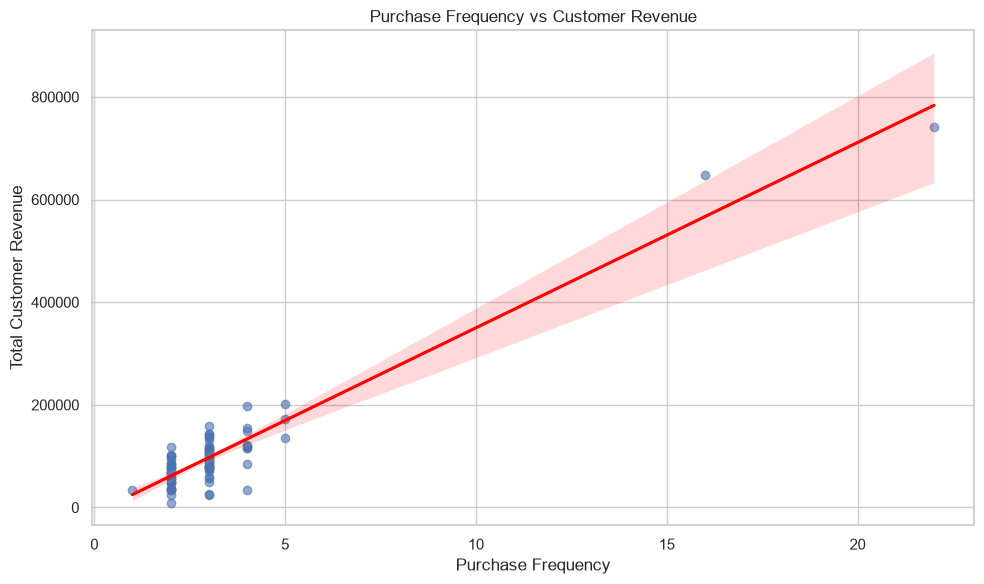

Pearson Correlation: 0.95
Spearman Correlation: 0.636


In [30]:
# Bivariate Analysis - Frequency vs Monetary

customer_fm = pd.merge(
    customer_frequency,
    customer_revenue,
    on="CUSTOMERNAME"
)

plt.figure(figsize=(10, 6))

sns.regplot(
    data=customer_fm,
    x="Frequency",
    y="Total_Revenue",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Purchase Frequency vs Customer Revenue")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Customer Revenue")
plt.tight_layout()
plt.show()

print("Pearson Correlation:",
      round(customer_fm["Frequency"].corr(
          customer_fm["Total_Revenue"],
          method="pearson"
      ), 3))

print("Spearman Correlation:",
      round(customer_fm["Frequency"].corr(
          customer_fm["Total_Revenue"],
          method="spearman"
      ), 3))


Purchase Frequency vs Customer Revenue — Key Findings

Purchase Frequency memiliki korelasi positif sangat kuat terhadap Customer Revenue berdasarkan Pearson (r = 0,950).

Korelasi Spearman sebesar 0,636 menunjukkan hubungan positif yang lebih moderat ketika dianalisis berdasarkan peringkat.

Perbedaan kedua nilai korelasi mengindikasikan kemungkinan pengaruh pelanggan dengan frekuensi pembelian ekstrem terhadap hubungan linear.

Conclusion: Frekuensi pembelian berkaitan dengan total nilai pelanggan dan menjadi variabel penting dalam segmentasi RFM.

## Outlier Sensitivity Analysis

In [31]:
# Correlation Sensitivity Analysis

# Customers with normal purchase frequency (1–5 orders)
customer_fm_normal = customer_fm[
    customer_fm["Frequency"] <= 5
]

print("Original Customers:", len(customer_fm))
print("Customers without extreme frequency:",
      len(customer_fm_normal))

print("\nOriginal Pearson:",
      round(customer_fm["Frequency"].corr(
          customer_fm["Total_Revenue"]
      ), 3))

print("Pearson without extreme customers:",
      round(customer_fm_normal["Frequency"].corr(
          customer_fm_normal["Total_Revenue"]
      ), 3))

print("\nOriginal Spearman:",
      round(customer_fm["Frequency"].corr(
          customer_fm["Total_Revenue"],
          method="spearman"
      ), 3))

print("Spearman without extreme customers:",
      round(customer_fm_normal["Frequency"].corr(
          customer_fm_normal["Total_Revenue"],
          method="spearman"
      ), 3))

Original Customers: 89
Customers without extreme frequency: 87

Original Pearson: 0.95
Pearson without extreme customers: 0.646

Original Spearman: 0.636
Spearman without extreme customers: 0.609


Purchase Frequency vs Customer Revenue — Key Findings

Purchase Frequency dan Customer Revenue memiliki korelasi Pearson sebesar 0,950 dan Spearman sebesar 0,636.

Setelah dua pelanggan dengan frekuensi transaksi ekstrem dikeluarkan sementara, korelasi Pearson menurun menjadi 0,646, sedangkan Spearman relatif stabil pada 0,609.

Hasil ini menunjukkan adanya pengaruh nilai ekstrem terhadap korelasi linear, tetapi hubungan positif antara Frequency dan Monetary tetap terlihat pada mayoritas pelanggan.

Conclusion: Purchase Frequency merupakan indikator penting dalam memahami perbedaan nilai pelanggan. Analisis RFM diperlukan untuk menggabungkan Frequency, Monetary, dan Recency dalam mengidentifikasi segmen pelanggan bernilai tinggi.

## Customer Recency vs Revenue

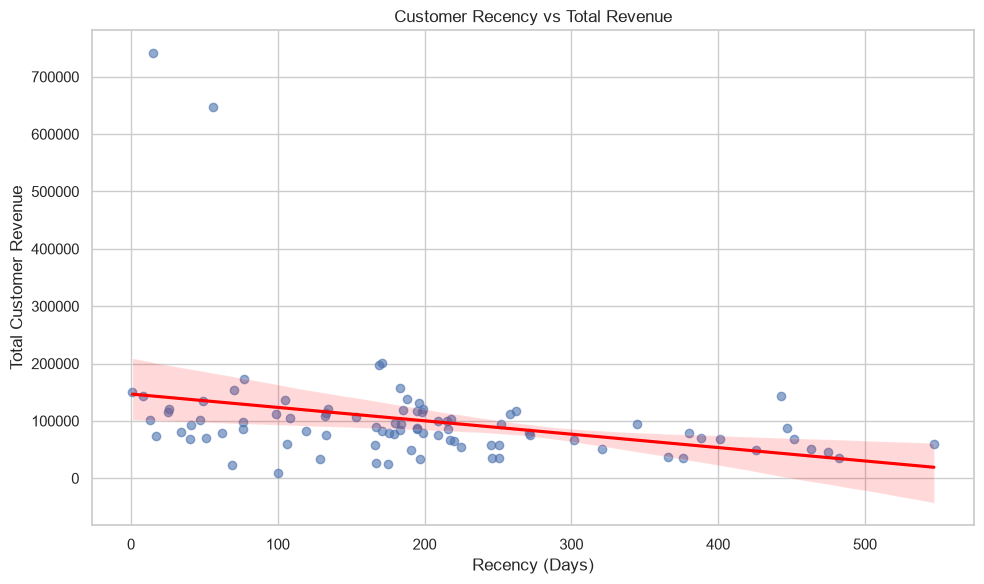

Pearson Correlation: -0.301
Spearman Correlation: -0.378


In [32]:

# Bivariate Analysis - Recency vs Monetary

customer_rm = pd.merge(
    customer_recency,
    customer_revenue,
    on="CUSTOMERNAME"
)

plt.figure(figsize=(10, 6))

sns.regplot(
    data=customer_rm,
    x="Recency",
    y="Total_Revenue",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Customer Recency vs Total Revenue")
plt.xlabel("Recency (Days)")
plt.ylabel("Total Customer Revenue")
plt.tight_layout()
plt.show()

print("Pearson Correlation:",
      round(customer_rm["Recency"].corr(
          customer_rm["Total_Revenue"]
      ), 3))

print("Spearman Correlation:",
      round(customer_rm["Recency"].corr(
          customer_rm["Total_Revenue"],
          method="spearman"
      ), 3))

Customer Recency vs Revenue — Key Findings

Recency memiliki korelasi negatif terhadap Customer Revenue, dengan Pearson sebesar -0,301 dan Spearman sebesar -0,378.

Pelanggan yang lebih baru melakukan transaksi cenderung memiliki akumulasi revenue lebih tinggi, meskipun hubungan tersebut relatif lemah hingga moderat.

Terdapat pelanggan dengan Recency tinggi yang masih memiliki historical revenue cukup besar, mengindikasikan potensi customer reactivation.

Conclusion: Recency perlu dianalisis bersama Frequency dan Monetary untuk mengidentifikasi pelanggan bernilai tinggi yang masih aktif serta pelanggan potensial yang sudah lama tidak bertransaksi.

## Customer Recency vs Purchase Frequency

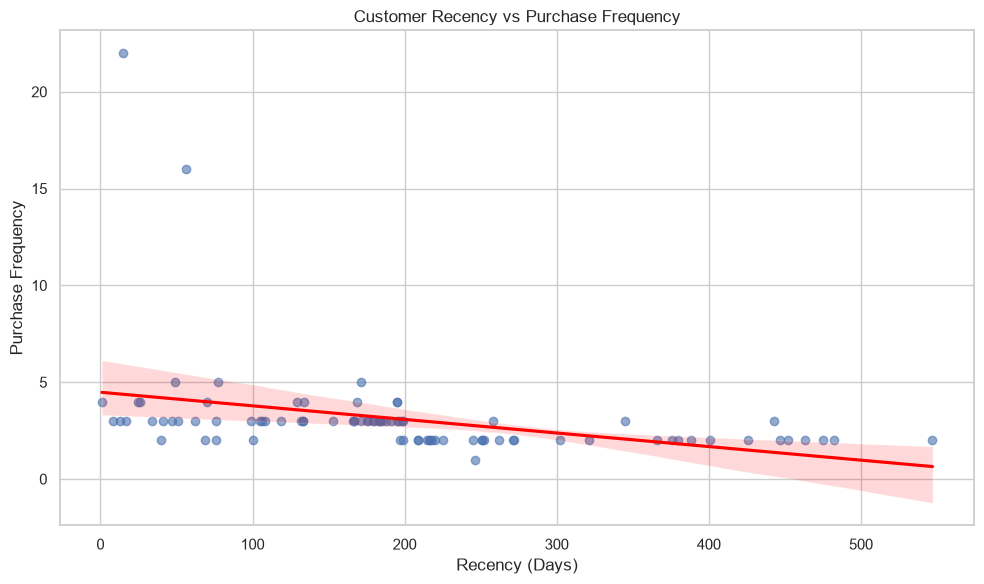

Pearson Correlation: -0.344
Spearman Correlation: -0.666


In [34]:
# Bivariate Analysis - Recency vs Frequency

customer_rf = pd.merge(
    customer_recency,
    customer_frequency,
    on="CUSTOMERNAME"
)

plt.figure(figsize=(10, 6))

sns.regplot(
    data=customer_rf,
    x="Recency",
    y="Frequency",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Customer Recency vs Purchase Frequency")
plt.xlabel("Recency (Days)")
plt.ylabel("Purchase Frequency")
plt.tight_layout()
plt.show()

print("Pearson Correlation:",
      round(customer_rf["Recency"].corr(
          customer_rf["Frequency"]
      ), 3))

print("Spearman Correlation:",
      round(customer_rf["Recency"].corr(
          customer_rf["Frequency"],
          method="spearman"
      ), 3))


Recency vs Purchase Frequency — Key Findings

Recency dan Purchase Frequency memiliki korelasi negatif dengan Pearson sebesar -0,344 dan Spearman sebesar -0,666.

Korelasi Spearman menunjukkan bahwa pelanggan dengan frekuensi pembelian lebih tinggi cenderung memiliki aktivitas transaksi yang lebih baru.

Mayoritas pelanggan dengan Recency tinggi memiliki frekuensi pembelian relatif rendah, sehingga berpotensi menjadi kelompok prioritas untuk analisis customer reactivation.

Conclusion: Kombinasi Recency, Frequency, dan Monetary diperlukan untuk memahami perilaku pelanggan secara lebih menyeluruh serta menentukan prioritas strategi retention dan reactivation.

# Multivariate Analysis

## Create Customer-Level Dataset

In [36]:
# Multivariate Analysis - Customer Level Dataset

customer_analysis = (
    customer_recency[
        ["CUSTOMERNAME", "Recency"]
    ]
    .merge(
        customer_frequency,
        on="CUSTOMERNAME"
    )
    .merge(
        customer_revenue,
        on="CUSTOMERNAME"
    )
)

# Average Order Value per customer
customer_analysis["AOV"] = (
    customer_analysis["Total_Revenue"] /
    customer_analysis["Frequency"]
)

# Number of distinct product categories purchased
product_diversity = (
    df_rfm.groupby("CUSTOMERNAME")["PRODUCTLINE"]
    .nunique()
    .reset_index(name="Product_Diversity")
)

customer_analysis = customer_analysis.merge(
    product_diversity,
    on="CUSTOMERNAME"
)

print("Customer Analysis Shape:")
print(customer_analysis.shape)

display(customer_analysis.head(10))


Customer Analysis Shape:
(89, 6)


,CUSTOMERNAME,Recency,Frequency,Total_Revenue,AOV,Product_Diversity
0,"AV Stores, Co.",183,3,"157,807.81","52,602.60",4
1,Alpha Cognac,51,3,"70,488.44","23,496.15",4
2,Amica Models & Co.,252,2,"94,117.26","47,058.63",5
3,"Anna's Decorations, Ltd",70,4,"153,996.13","38,499.03",4
4,Atelier graphique,175,3,"24,179.96","8,059.99",3
5,"Australian Collectables, Ltd",321,2,"50,213.37","25,106.69",2
6,"Australian Collectors, Co.",171,5,"200,995.41","40,199.08",5
7,"Australian Gift Network, Co",106,3,"59,469.12","19,823.04",6
8,Auto Assoc. & Cie.,220,2,"64,834.32","32,417.16",3
9,Auto Canal Petit,41,3,"93,170.66","31,056.89",2


## Multivariate Correlation Heatmap

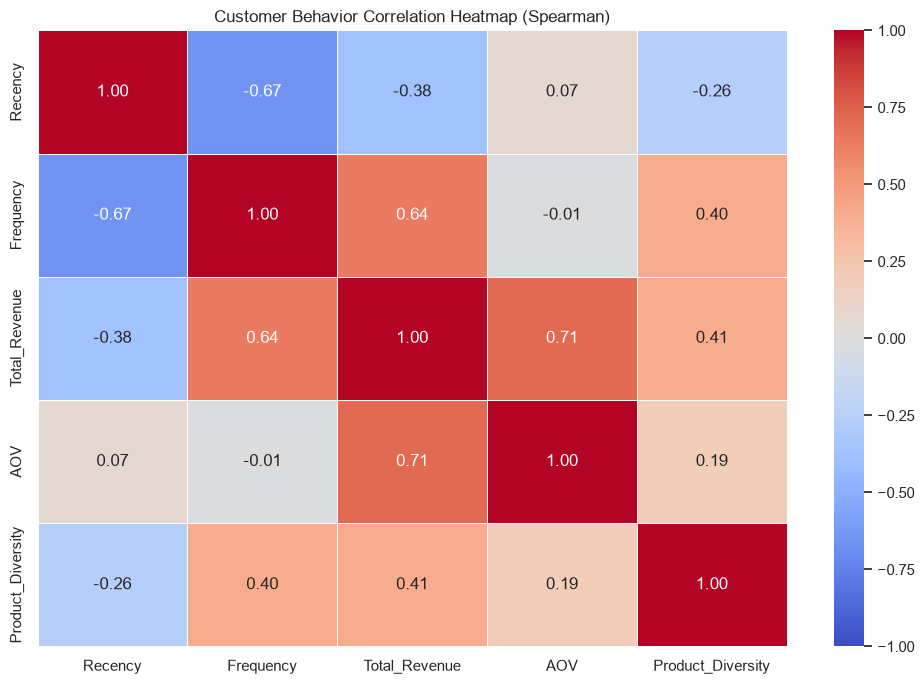

,Recency,Frequency,Total_Revenue,AOV,Product_Diversity
Recency,1.00,-0.67,-0.38,0.07,-0.26
Frequency,-0.67,1.00,0.64,-0.01,0.40
Total_Revenue,-0.38,0.64,1.00,0.71,0.41
AOV,0.07,-0.01,0.71,1.00,0.19
Product_Diversity,-0.26,0.40,0.41,0.19,1.00


In [37]:
# Multivariate Analysis - Spearman Correlation Heatmap

corr_cols = [
    "Recency",
    "Frequency",
    "Total_Revenue",
    "AOV",
    "Product_Diversity"
]

corr_matrix = customer_analysis[corr_cols].corr(
    method="spearman"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Customer Behavior Correlation Heatmap (Spearman)")
plt.tight_layout()
plt.show()

display(corr_matrix.round(3))


Multivariate Correlation Analysis — Key Findings

Customer Revenue memiliki korelasi positif dengan AOV (r = 0,71) dan Purchase Frequency (r = 0,64), menunjukkan keterkaitan kedua metrik dengan nilai pelanggan.

Frequency dan AOV hampir tidak memiliki hubungan monoton (r = -0,01), mengindikasikan bahwa pelanggan dengan frekuensi pembelian tinggi belum tentu memiliki rata-rata nilai transaksi yang tinggi.

Recency memiliki korelasi negatif dengan Frequency (r = -0,67), menunjukkan bahwa pelanggan yang lebih sering bertransaksi cenderung memiliki aktivitas pembelian yang lebih baru.

Product Diversity memiliki korelasi positif moderat dengan Total Revenue (r = 0,41), sehingga dapat dieksplorasi sebagai variabel tambahan dalam analisis perilaku pelanggan.

Conclusion: Hasil analisis menunjukkan pentingnya menggabungkan Recency, Frequency, dan Monetary untuk memahami perbedaan perilaku serta nilai pelanggan. AOV dan Product Diversity dapat digunakan untuk memperkaya rekomendasi strategi retention dan upselling.

## Multivariate Customer Behavior Analysis

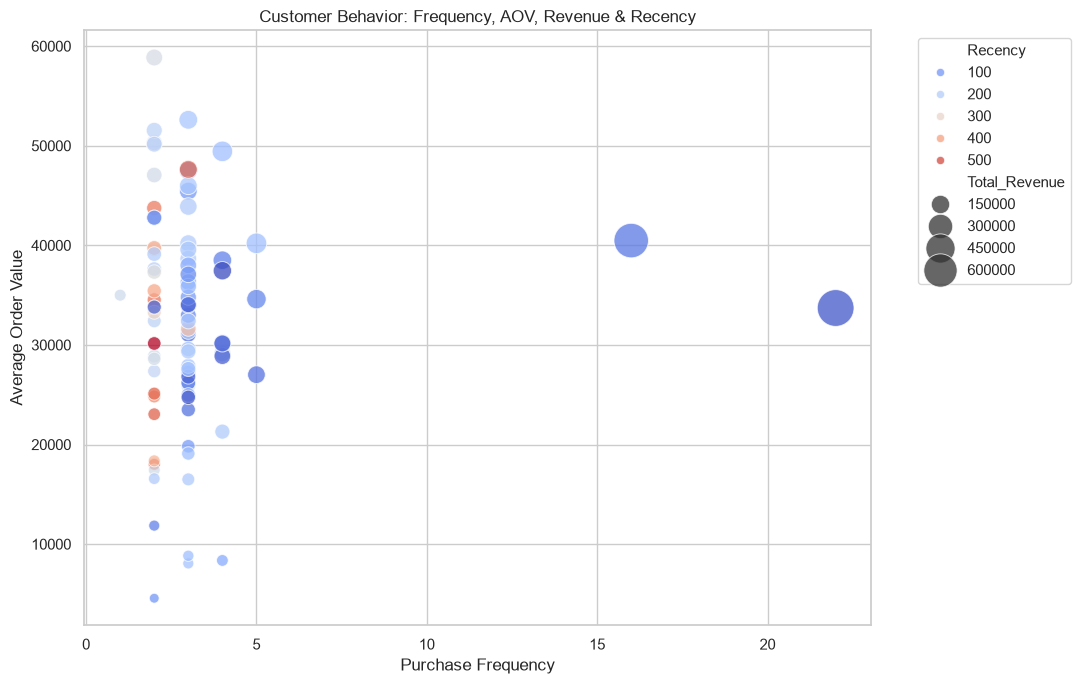

In [38]:
# Multivariate Analysis - Customer Behavior

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=customer_analysis,
    x="Frequency",
    y="AOV",
    hue="Recency",
    size="Total_Revenue",
    sizes=(50, 700),
    palette="coolwarm",
    alpha=0.75
)

plt.title("Customer Behavior: Frequency, AOV, Revenue & Recency")
plt.xlabel("Purchase Frequency")
plt.ylabel("Average Order Value")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


Multivariate Customer Behavior — Key Findings

Mayoritas pelanggan memiliki frekuensi pembelian 2–5 transaksi dengan variasi AOV yang cukup besar.

Dua pelanggan dengan frekuensi 16 dan 22 transaksi memiliki kontribusi revenue yang sangat tinggi serta Recency relatif rendah.

Frequency dan AOV hampir tidak memiliki hubungan monoton (r = -0,01), menunjukkan bahwa pelanggan yang lebih sering bertransaksi belum tentu memiliki nilai pembelian rata-rata lebih tinggi.

Perbedaan kombinasi Frequency, AOV, dan Recency mengindikasikan adanya karakteristik perilaku pembelian yang beragam antarpelanggan.

Conclusion: Customer Segmentation menggunakan RFM diperlukan untuk mengidentifikasi high-value customers, pelanggan potensial untuk upselling, serta peluang customer reactivation berdasarkan perilaku dan nilai transaksi historis.

## RFM Scoring (1–5)

In [39]:

# RFM Scoring (1-5)

rfm = customer_analysis.copy()

# Recency: lower is better
rfm["R_Score"] = np.ceil(
    rfm["Recency"].rank(
        pct=True,
        ascending=False,
        method="average"
    ) * 5
).astype(int)

# Frequency: higher is better
rfm["F_Score"] = np.ceil(
    rfm["Frequency"].rank(
        pct=True,
        ascending=True,
        method="average"
    ) * 5
).astype(int)

# Monetary: higher is better
rfm["M_Score"] = np.ceil(
    rfm["Total_Revenue"].rank(
        pct=True,
        ascending=True,
        method="average"
    ) * 5
).astype(int)

# Total RFM Score
rfm["RFM_Score"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

display(rfm.head(10))

print("\nRFM Score Distribution:")
display(rfm["RFM_Score"].value_counts().sort_index())

,CUSTOMERNAME,Recency,Frequency,Total_Revenue,AOV,Product_Diversity,R_Score,F_Score,M_Score,RFM_Score
0,"AV Stores, Co.",183,3,"157,807.81","52,602.60",4,3,4,5,12
1,Alpha Cognac,51,3,"70,488.44","23,496.15",4,5,4,2,11
2,Amica Models & Co.,252,2,"94,117.26","47,058.63",5,2,2,3,7
3,"Anna's Decorations, Ltd",70,4,"153,996.13","38,499.03",4,5,5,5,15
4,Atelier graphique,175,3,"24,179.96","8,059.99",3,3,4,1,8
5,"Australian Collectables, Ltd",321,2,"50,213.37","25,106.69",2,1,2,1,4
6,"Australian Collectors, Co.",171,5,"200,995.41","40,199.08",5,3,5,5,13
7,"Australian Gift Network, Co",106,3,"59,469.12","19,823.04",6,4,4,2,10
8,Auto Assoc. & Cie.,220,2,"64,834.32","32,417.16",3,2,2,2,6
9,Auto Canal Petit,41,3,"93,170.66","31,056.89",2,5,4,3,12



RFM Score Distribution:


RFM_Score
4      8
5      8
6      8
7      5
8      7
9      4
10    12
11     8
12    13
13     5
14     5
15     6
Name: count, dtype: int64

Seluruh 89 customer sudah mendapatkan RFM Score. Total frekuensi pada output sesuai dengan jumlah pelanggan kita.



Skor tertinggi adalah 15, artinya terdapat 6 pelanggan dengan kombinasi skor R, F, dan M yang maksimal.



Skor terendah adalah 4, bukan 3. Ini tidak otomatis menjadi masalah karena metode percentile ranking dan banyaknya nilai Frequency yang sama dapat membuat sebagian skor tidak muncul.



Skor 12 paling banyak ditemukan, yaitu pada 13 pelanggan

## RFM Score Validation

In [40]:

# Validate RFM Scores

print("Top 10 Customers by RFM Score")

display(
    rfm.sort_values(
        ["RFM_Score", "Total_Revenue"],
        ascending=[False, False]
    )[
        [
            "CUSTOMERNAME",
            "Recency",
            "Frequency",
            "Total_Revenue",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Score"
        ]
    ].head(10)
)

print("\nBottom 10 Customers by RFM Score")

display(
    rfm.sort_values(
        ["RFM_Score", "Total_Revenue"],
        ascending=[True, True]
    )[
        [
            "CUSTOMERNAME",
            "Recency",
            "Frequency",
            "Total_Revenue",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Score"
        ]
    ].head(10)
)


Top 10 Customers by RFM Score


,CUSTOMERNAME,Recency,Frequency,Total_Revenue,R_Score,F_Score,M_Score,RFM_Score
32,Euro Shopping Channel,15,22,"741,512.50",5,5,5,15
53,Mini Gifts Distributors Ltd.,56,16,"647,596.31",5,5,5,15
3,"Anna's Decorations, Ltd",70,4,"153,996.13",5,5,5,15
67,Salzburg Collectables,1,4,"149,798.63",5,5,5,15
63,Reims Collectables,49,5,"135,042.94",5,5,5,15
79,"Tokyo Collectables, Ltd",26,4,"120,562.74",5,5,5,15
55,Muscle Machine Inc,169,4,"197,736.94",4,5,5,14
30,"Dragon Souveniers, Ltd.",77,5,"172,989.68",4,5,5,14
41,L'ordine Souveniers,8,3,"142,601.33",5,4,5,14
76,Technics Stores Inc.,134,4,"120,783.07",4,5,5,14



Bottom 10 Customers by RFM Score


,CUSTOMERNAME,Recency,Frequency,Total_Revenue,R_Score,F_Score,M_Score,RFM_Score
12,"Bavarian Collectables Imports, Co.",246,1,"34,993.92",2,1,1,4
29,"Double Decker Gift Stores, Ltd",482,2,"36,019.04",1,2,1,4
16,Cambridge Collectables Co.,376,2,"36,163.62",1,2,1,4
77,Tekni Collectables Inc.,366,2,"36,709.19",1,2,1,4
87,West Coast Collectables Co.,475,2,"46,084.64",1,2,1,4
15,CAF Imports,426,2,"49,642.05",1,2,1,4
5,"Australian Collectables, Ltd",321,2,"50,213.37",1,2,1,4
70,Signal Collectibles Ltd.,463,2,"50,218.51",1,2,1,4
36,Gifts4AllAges.com,251,2,"34,892.99",2,2,1,5
40,"Iberia Gift Imports, Corp.",225,2,"54,723.62",2,2,1,5


Top 10 Customers

Euro Shopping Channel: RFM Score 15, Frequency 22, Revenue 741.512,50, dan Recency 15 hari. Pelanggan ini unggul pada ketiga komponen RFM.



Mini Gifts Distributors Ltd.: RFM Score 15, Frequency 16, Revenue 647.596,31, dan Recency 56 hari.



Salzburg Collectables: RFM Score 15 dengan Recency hanya 1 hari, menunjukkan pembelian yang sangat baru pada akhir periode pengamatan.

Bottom 10 Customers

Recency tinggi, sekitar 225–482 hari.



Frequency rendah, hanya 1–2 transaksi.



Total Revenue relatif rendah.

## Customer Segmentation

In [43]:

# RFM Customer Segmentation

rfm["Segment"] = np.select(
    [
        rfm["RFM_Score"] >= 12,
        rfm["RFM_Score"] >= 9
    ],
    [
        "High Value",
        "Potential"
    ],
    default="Needs Attention"
)

# Customer Distribution by Segment
segment_distribution = (
    rfm["Segment"]
    .value_counts()
    .reset_index()
)

segment_distribution.columns = [
    "Segment",
    "Total_Customers"
]

segment_distribution["Percentage"] = (
    segment_distribution["Total_Customers"]
    / len(rfm) * 100
).round(2)

display(segment_distribution)

,Segment,Total_Customers,Percentage
0,Needs Attention,36,40.45
1,High Value,29,32.58
2,Potential,24,26.97


In [44]:
# RFM Segment Performance Analysis

segment_performance = rfm.groupby("Segment").agg(
    Total_Customers=("CUSTOMERNAME", "count"),
    Total_Revenue=("Total_Revenue", "sum"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Total_Revenue", "mean"),
    Avg_AOV=("AOV", "mean")
).reset_index()

# Revenue contribution
segment_performance["Revenue_Contribution"] = (
    segment_performance["Total_Revenue"] /
    segment_performance["Total_Revenue"].sum() * 100
)

display(segment_performance.round(2))

,Segment,Total_Customers,Total_Revenue,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_AOV,Revenue_Contribution
0,High Value,29,"4,799,472.19",94.86,4.55,"165,499.04","36,615.49",53.21
1,Needs Attention,36,"2,226,654.74",292.67,2.03,"61,851.52","31,070.70",24.69
2,Potential,24,"1,992,967.01",169.88,3.00,"83,040.29","28,331.78",22.10


RFM Customer Segmentation — Key Findings

Segmen High Value terdiri dari 32,58% pelanggan, tetapi memberikan kontribusi terbesar terhadap total revenue, yaitu 53,21%.

Segmen Needs Attention mencakup 40,45% pelanggan, tetapi hanya menyumbang 24,69% revenue, dengan Average Recency tertinggi sebesar 292,67 hari.

Segmen Potential menyumbang 22,10% revenue dengan rata-rata frekuensi pembelian sebanyak 3 transaksi.

Conclusion: Hasil RFM menunjukkan adanya perbedaan nilai dan aktivitas pelanggan antarsekmen. Bisnis perlu memprioritaskan retention pelanggan High Value, mengembangkan pelanggan Potential, serta mengevaluasi peluang reactivation pada segmen Needs Attention.

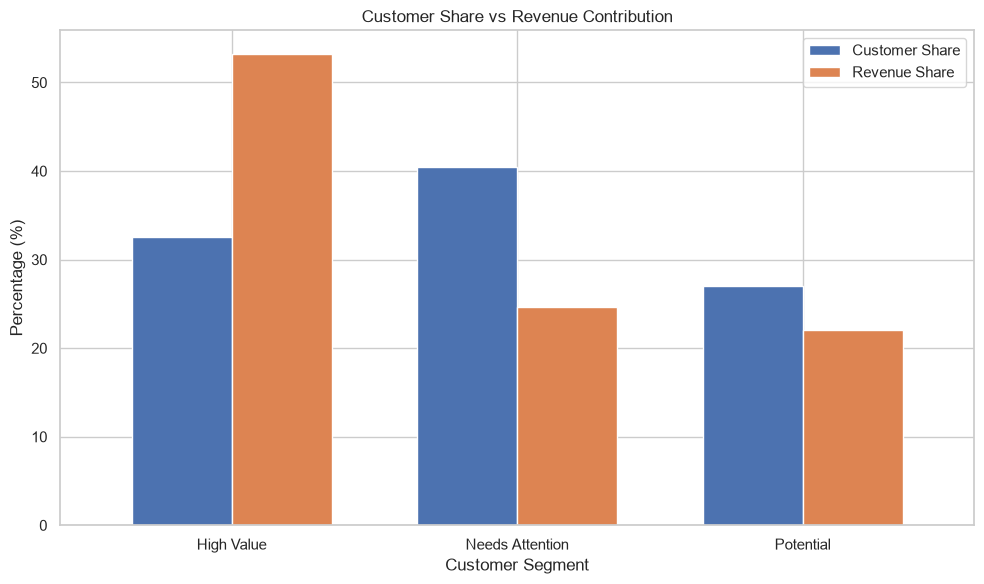

In [45]:

# Customer Share vs Revenue Share

segment_comparison = segment_performance.copy()

segment_comparison["Customer_Share"] = (
    segment_comparison["Total_Customers"]
    / segment_comparison["Total_Customers"].sum() * 100
)

segment_comparison = segment_comparison.set_index("Segment")

segment_comparison[
    ["Customer_Share", "Revenue_Contribution"]
].plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title("Customer Share vs Revenue Contribution")
plt.xlabel("Customer Segment")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Customer Share", "Revenue Share"])
plt.tight_layout()
plt.show()


Customer Share vs Revenue Contribution — Key Findings

Segmen High Value mencakup 32,58% pelanggan, tetapi menghasilkan 53,21% total revenue, menunjukkan kontribusi nilai pelanggan yang relatif tinggi.

Segmen Needs Attention merupakan kelompok terbesar (40,45%), tetapi hanya menyumbang 24,69% revenue.

Segmen Potential berkontribusi sebesar 22,10% revenue dari 26,97% total pelanggan.

Conclusion: Hasil segmentasi menunjukkan pentingnya mempertahankan pelanggan High Value, meningkatkan potensi pembelian segmen Potential, dan mengevaluasi peluang reactivation pada pelanggan Needs Attention.

In [46]:
# Identify Customer Reactivation Opportunities

recency_threshold = rfm["Recency"].quantile(0.75)

reactivation_candidates = (
    rfm[
        rfm["Recency"] >= recency_threshold
    ]
    .sort_values(
        "Total_Revenue",
        ascending=False
    )
)

print("Recency Threshold:", recency_threshold)
print("Total Candidates:", len(reactivation_candidates))

display(
    reactivation_candidates[
        [
            "CUSTOMERNAME",
            "Segment",
            "Recency",
            "Frequency",
            "Total_Revenue",
            "RFM_Score"
        ]
    ].head(10)
)


Recency Threshold: 251.0
Total Candidates: 23


,CUSTOMERNAME,Segment,Recency,Frequency,Total_Revenue,RFM_Score
68,"Saveley & Henriot, Co.",Potential,443,3,"142,874.25",10
84,"Vida Sport, Ltd",Needs Attention,262,2,"117,713.56",8
39,Herkku Gifts,Potential,258,3,"111,640.28",10
26,Danish Wholesale Imports,Potential,345,3,"94,950.12",9
2,Amica Models & Co.,Needs Attention,252,2,"94,117.26",7
21,Collectable Mini Designs Co.,Needs Attention,447,2,"87,489.23",6
75,Super Scale Inc.,Needs Attention,380,2,"79,472.07",6
56,"Norway Gifts By Mail, Co.",Needs Attention,271,2,"79,224.23",7
65,"Royal Canadian Collectables, Ltd.",Needs Attention,272,2,"74,634.85",5
28,Diecast Collectables,Needs Attention,388,2,"70,859.78",5


Customer Reactivation Opportunities — Key Findings

Ditemukan sejumlah pelanggan dengan Recency tinggi yang masih memiliki historical revenue relatif besar.

Saveley & Henriot, Co. menjadi salah satu kandidat prioritas reactivation dengan Recency 443 hari dan total revenue 142.874,25.

Peluang reactivation ditemukan pada segmen Potential maupun Needs Attention, sehingga strategi reactivation perlu mempertimbangkan kombinasi Recency dan Monetary.

Conclusion: Bisnis dapat memprioritaskan pendekatan reactivation kepada pelanggan yang sudah lama tidak bertransaksi tetapi memiliki nilai pembelian historis tinggi, dengan mempertimbangkan siklus pembelian masing-masing pelanggan.

In [47]:
# Reactivation Opportunity Summary

reactivation_summary = (
    reactivation_candidates
    .groupby("Segment")
    .agg(
        Total_Customers=("CUSTOMERNAME", "count"),
        Historical_Revenue=("Total_Revenue", "sum"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean")
    )
    .reset_index()
)

reactivation_summary["Revenue_Contribution"] = (
    reactivation_summary["Historical_Revenue"] /
    rfm["Total_Revenue"].sum() * 100
)

display(reactivation_summary.round(2))

print(
    "Total Reactivation Candidates:",
    len(reactivation_candidates)
)

print(
    "Total Historical Revenue Contribution:",
    round(
        reactivation_candidates["Total_Revenue"].sum() /
        rfm["Total_Revenue"].sum() * 100,
        2
    ),
    "%"
)


,Segment,Total_Customers,Historical_Revenue,Avg_Recency,Avg_Frequency,Revenue_Contribution
0,Needs Attention,20,"1,264,159.00",369.25,2.00,14.02
1,Potential,3,"349,464.65",348.67,3.00,3.87


Total Reactivation Candidates: 23
Total Historical Revenue Contribution: 17.89 %


Customer Reactivation Opportunities — Key Findings

Sebanyak 23 pelanggan (25,84%) teridentifikasi sebagai kandidat reactivation berdasarkan Recency yang relatif tinggi.

Kelompok tersebut memiliki historical revenue sebesar 1,61 juta atau 17,89% dari total revenue.

Sebanyak 20 pelanggan berasal dari segmen Needs Attention, sedangkan 3 pelanggan berasal dari segmen Potential.

Pelanggan Potential memiliki rata-rata frekuensi pembelian lebih tinggi, sehingga dapat menjadi prioritas awal untuk strategi reactivation.

Conclusion: Strategi reactivation dapat difokuskan pada pelanggan dengan Recency tinggi dan nilai historis yang signifikan. Prioritas pendekatan perlu mempertimbangkan Monetary dan Frequency, bukan hanya lamanya pelanggan tidak bertransaksi.

In [49]:

# Export RFM Analysis Results

rfm.to_csv(
    "automobile_rfm_customers.csv",
    index=False
)

segment_performance.to_csv(
    "automobile_rfm_segment_summary.csv",
    index=False
)

df_rfm.to_csv(
    "automobile_sales_cleaned.csv",
    index=False
)

print("Export completed!")

print("\nRFM Customers:", rfm.shape)
print("Segment Summary:", segment_performance.shape)
print("Cleaned Sales:", df_rfm.shape)

Export completed!

RFM Customers: (89, 11)
Segment Summary: (3, 8)
Cleaned Sales: (2541, 20)
